Proper SGD Error (MSE): 0.18410583941396358


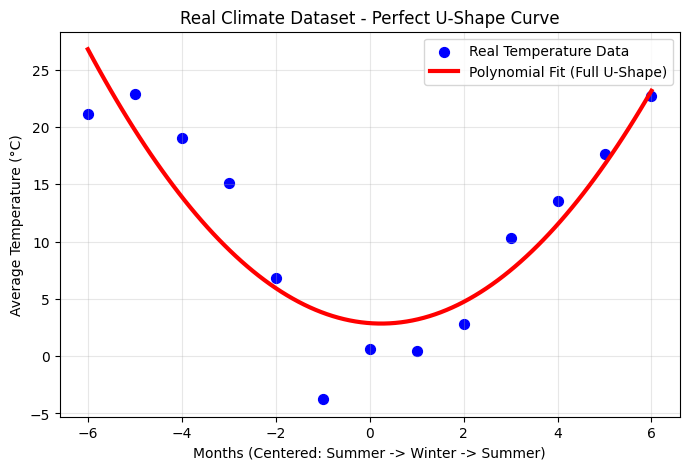

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error


df = pd.read_csv('/kaggle/input/datasets/yazanpc/temperatures/GlobalLandTemperaturesByMajorCity.csv')
df = df.dropna()


df_city = df[(df['City'] == 'Chicago') & (df['dt'] >= '2000-07-01') & (df['dt'] <= '2001-07-01')]
X = np.arange(len(df_city)).reshape(-1, 1)
y = df_city['AverageTemperature'].values
X_centered = X - np.mean(X)


poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X_centered)

scaler_X = StandardScaler()
X_poly_scaled = scaler_X.fit_transform(X_poly)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).ravel()


sgd = SGDRegressor(max_iter=3000, learning_rate='constant', eta0=0.01, random_state=42)
sgd.fit(X_poly_scaled, y_scaled)
mse = mean_squared_error(y_scaled, sgd.predict(X_poly_scaled))
print("Proper SGD Error (MSE):", mse)

plt.figure(figsize=(8, 5))
plt.scatter(X_centered, y, color='blue', s=50, label='Real Temperature Data')


X_grid = np.linspace(min(X_centered), max(X_centered), 100).reshape(-1, 1)
X_grid_poly = poly.transform(X_grid)
X_grid_poly_scaled = scaler_X.transform(X_grid_poly)

y_pred_scaled = sgd.predict(X_grid_poly_scaled)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))

plt.plot(X_grid, y_pred, color='red', linewidth=3, label='Polynomial Fit (Full U-Shape)')
plt.xlabel('Months (Centered: Summer -> Winter -> Summer)')
plt.ylabel('Average Temperature (°C)')
plt.title('Real Climate Dataset - Perfect U-Shape Curve')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
